## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Daniel Sebastian Castillo Baquero" # @param {"type":"string"}
carnet = 1000116730 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa debe administrar tareas tecnicas segun su prioridad y conectar seis dispositivos utilizando la menor cantidad total de cable. Primero se procesan las tareas con una cola de prioridad hecha con un Max-Heap y despues se conectan los dispositivos con el algoritmo de Kruskal.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

**Funcionales**

- RQF1: Construir un Max-Heap con las seis tareas usando MAX-HEAPIFY y BUILD-MAX-HEAP, mostrando el arreglo inicial, el Max-Heap resultante y su arbol.
- RQF2: Procesar las dos tareas de mayor prioridad con EXTRACT-MAX y agregar la tarea T07 manteniendo la propiedad del Max-Heap.
- RQF3: Graficar la posicion de los seis dispositivos y calcular automaticamente la distancia entre cada pareja.
- RQF4: Aplicar Kruskal de forma manual, evitando ciclos, hasta obtener exactamente 5 conexiones.
- RQF5: Graficar solo las conexiones del MST con su peso y la longitud total de cable.

**No Funcionales**

- RQNF1: El sistema no debe graficar menos de 6 dispositivos.
- RQNF2: El sistema debe seguir las propiedades del Max-Heap

## 3) Historias de usuario **[2 pts]**

**Historia 1: Atender tareas tecnicas.** Como encargado, quiero procesar primero la tarea de mayor prioridad; EXTRACT-MAX entrega la tarea y deja el arreglo como Max-Heap.

**Historia 2: Agregar una emergencia.** Como encargado, quiero agregar una tarea nueva, como la falla en el sistema contra incendios, y que suba hasta su lugar en el Max-Heap.

**Historia 3: Conectar dispositivos.** Como instalador, quiero conectar los seis dispositivos con la menor longitud total de cable, calculando cada cable con la distancia entre sus coordenadas.


## 4) Diagramas de flujo **[5 pts]**
**1.**

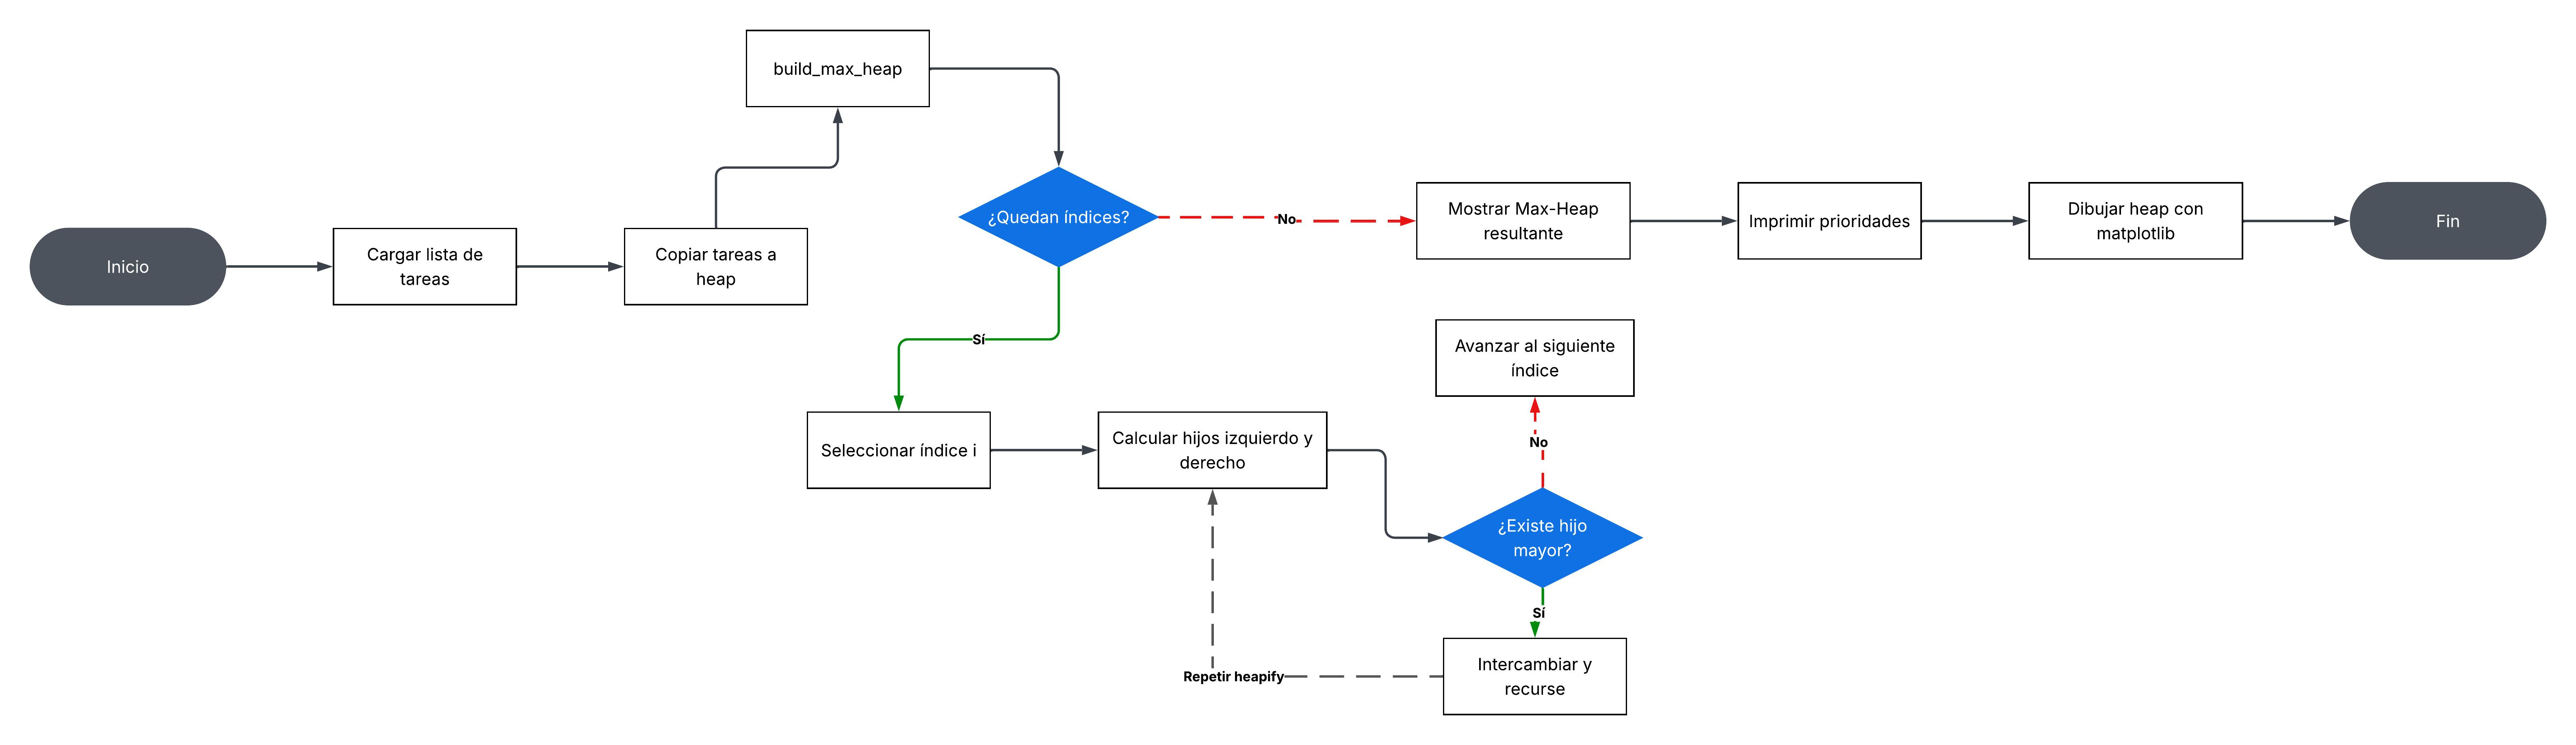

**2.**

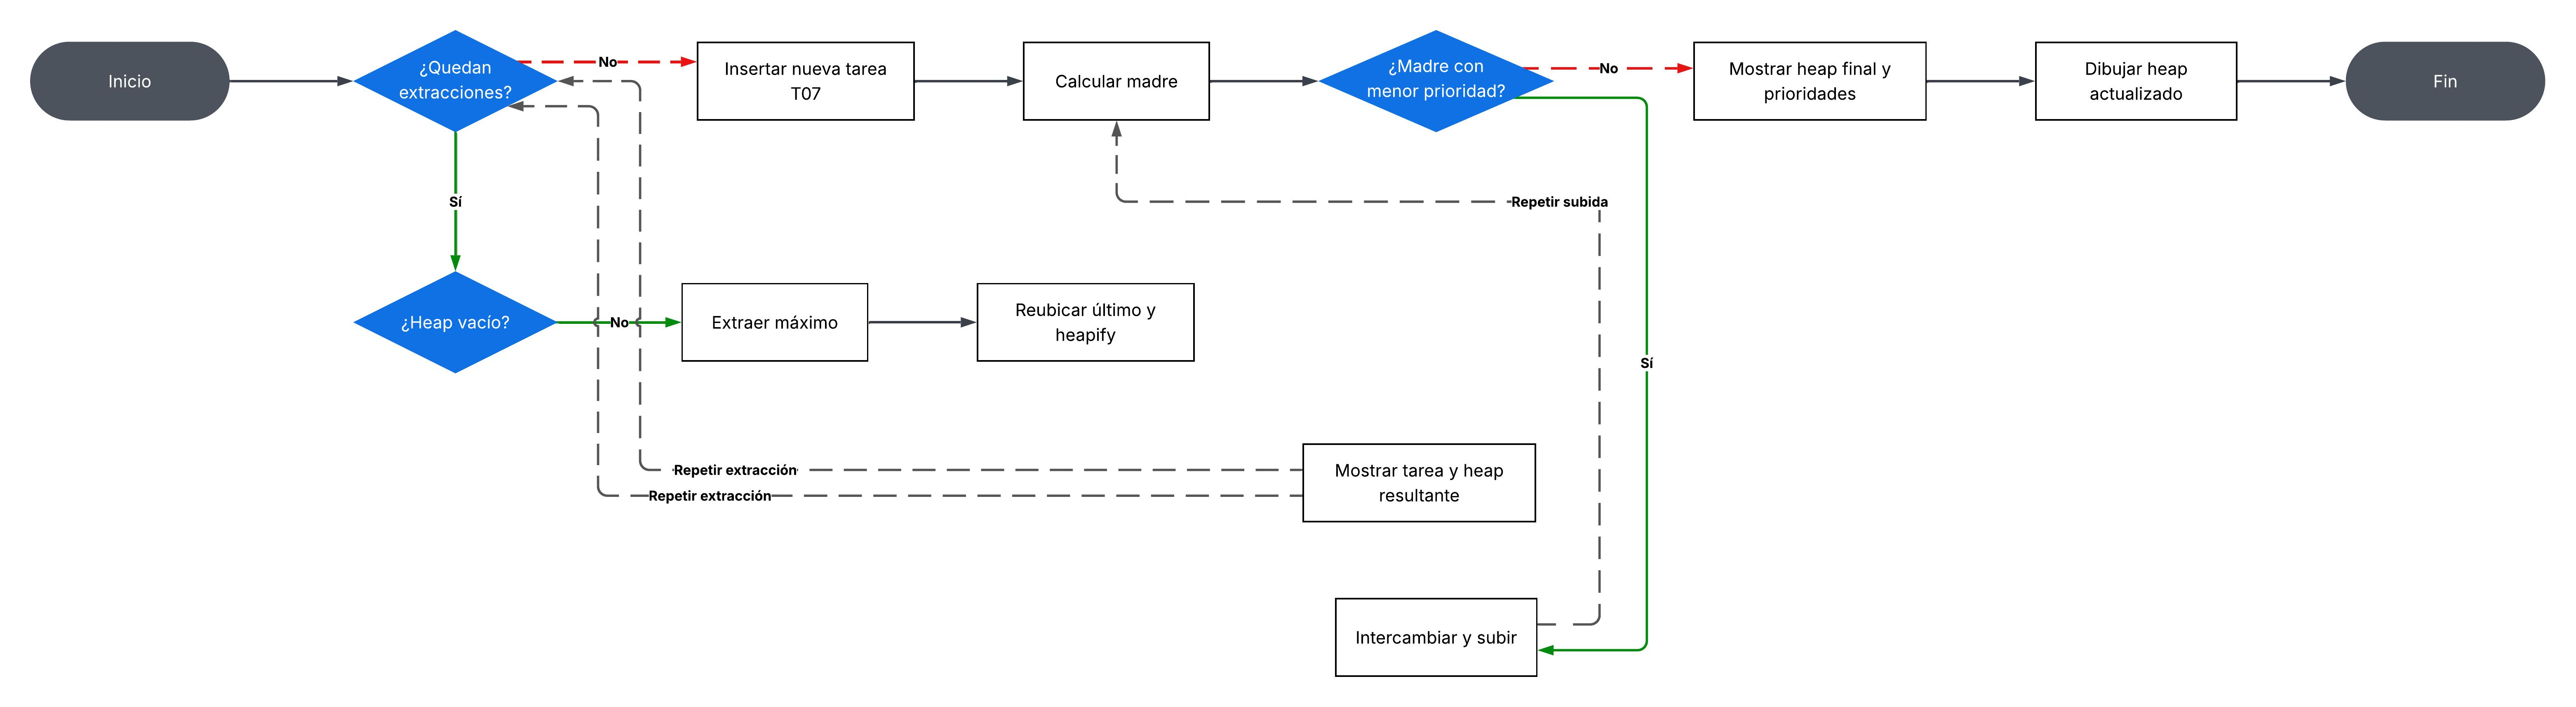

**3.**

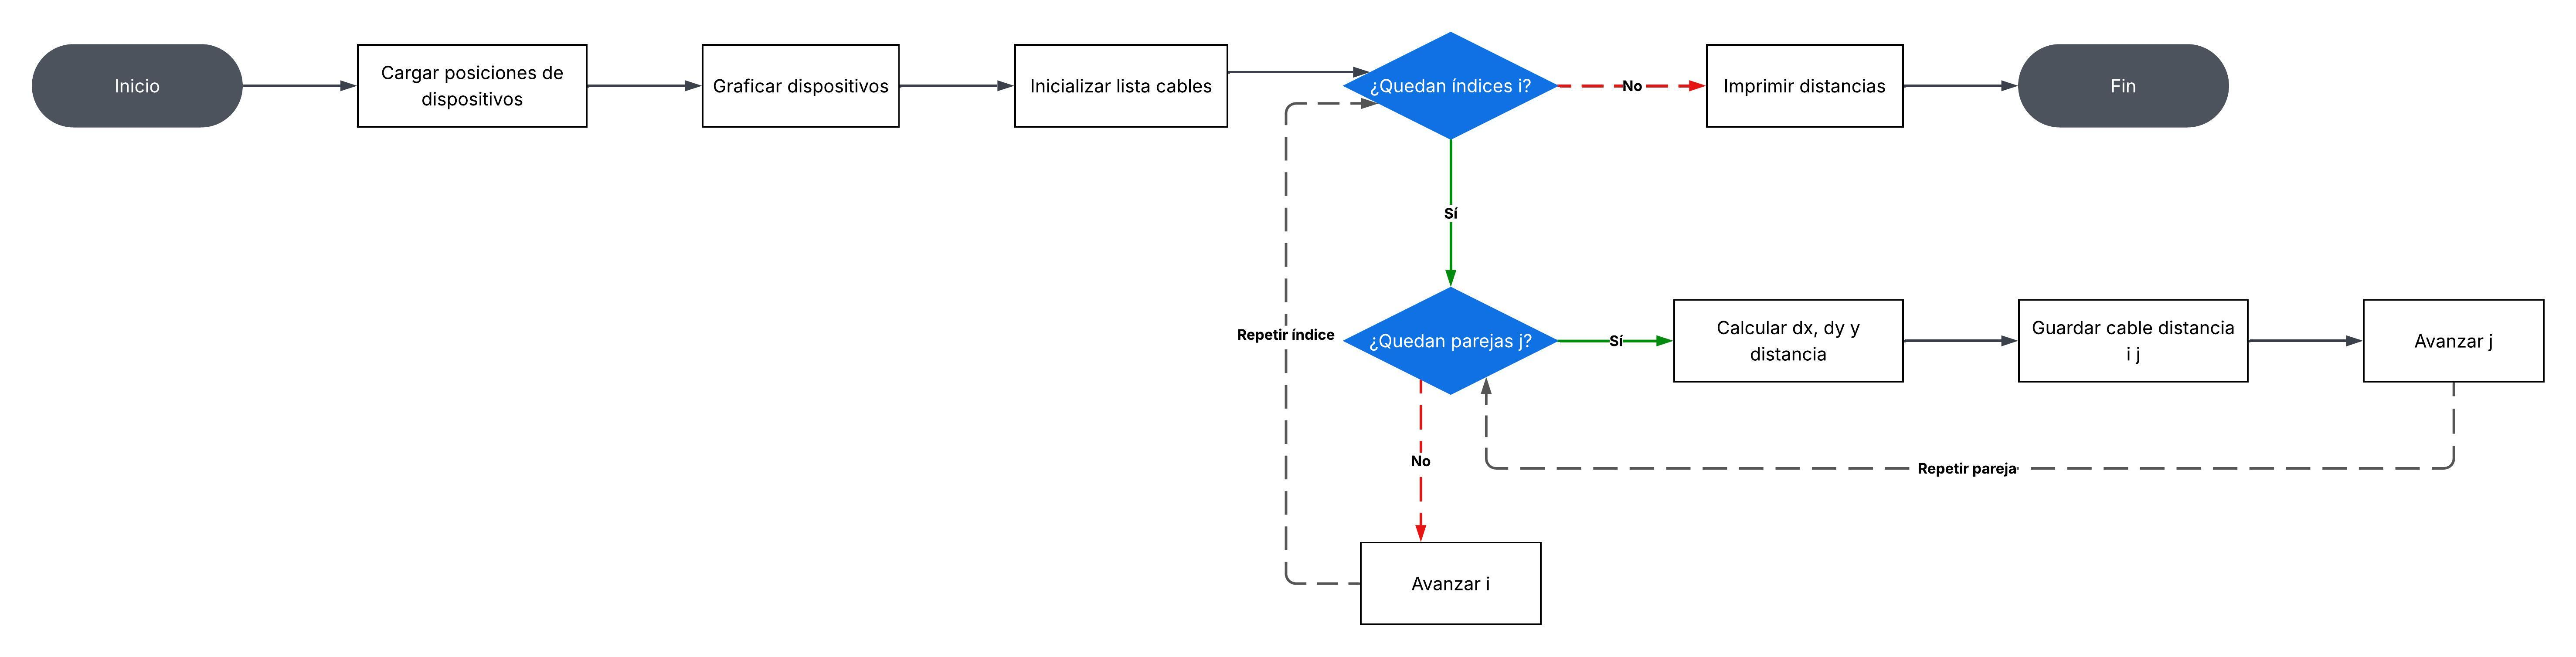

**4.**

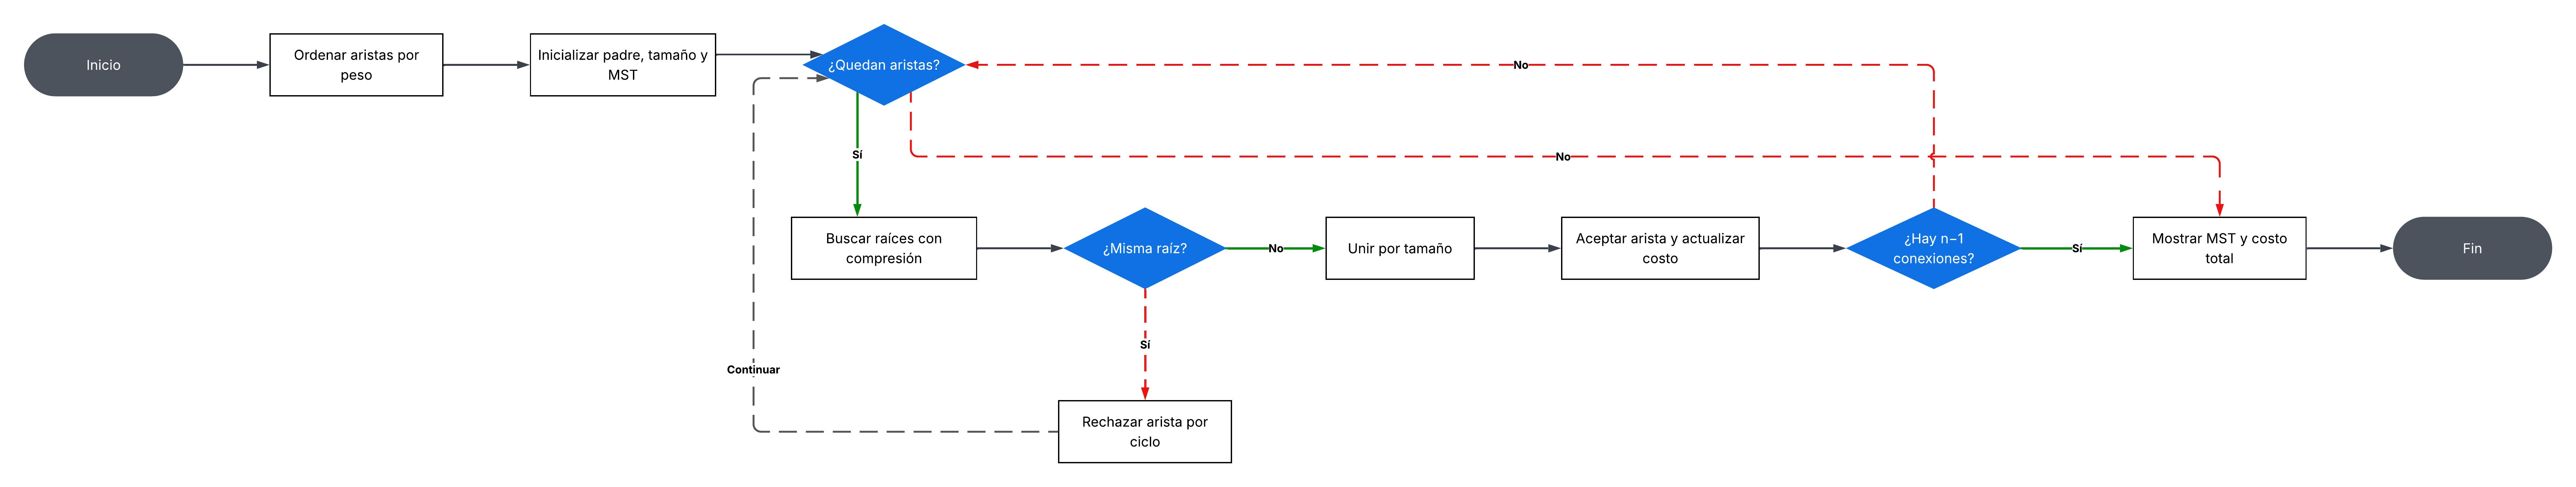

**5.**



### 5) Análisis de complejidad **[15 pts]**

**1.**

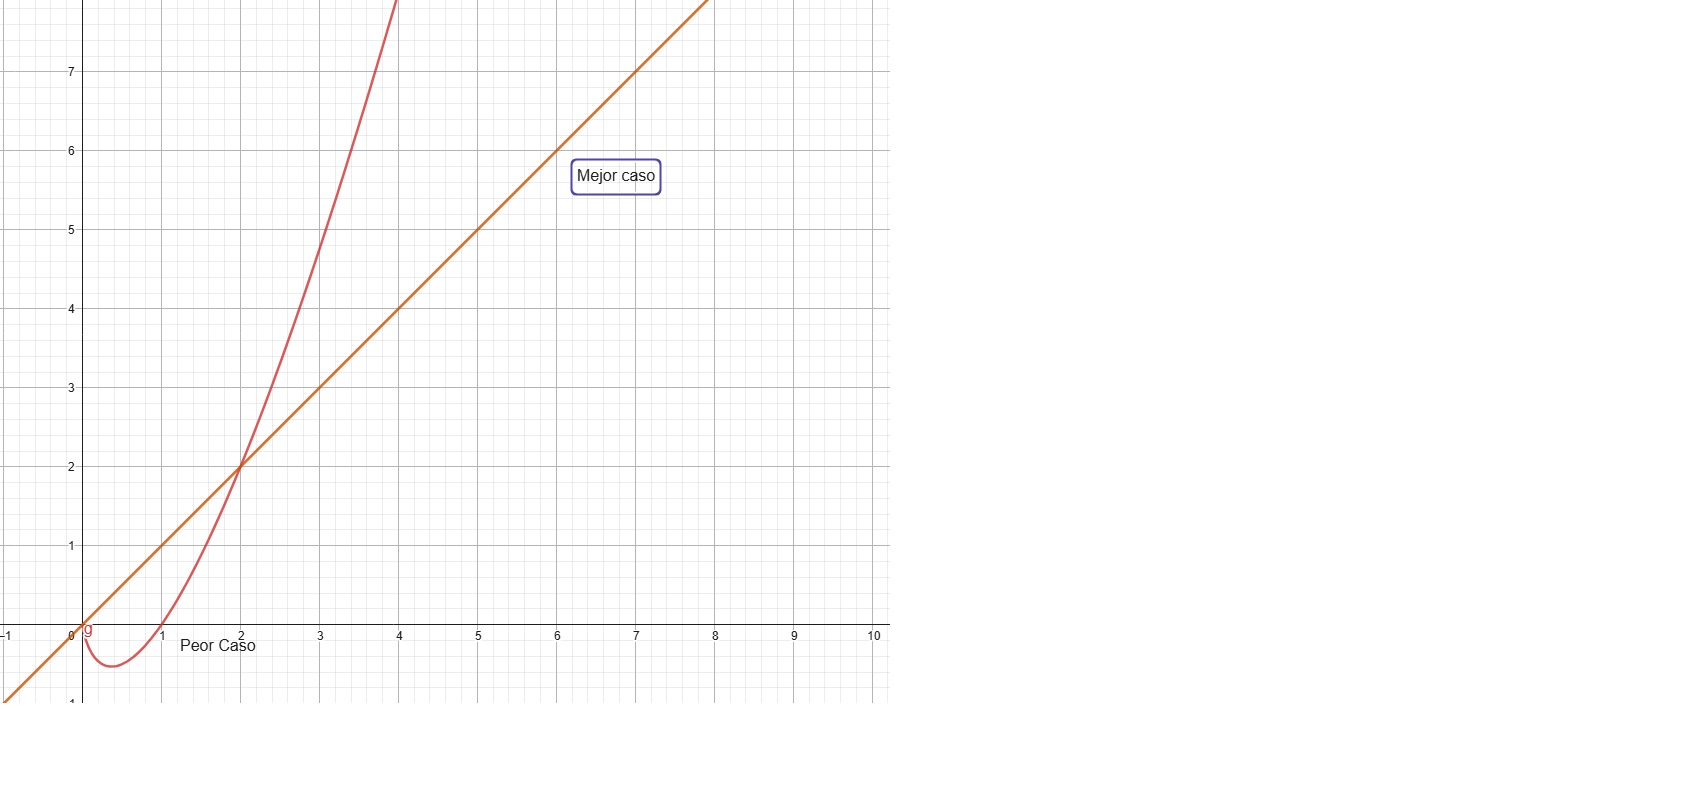

**2.**

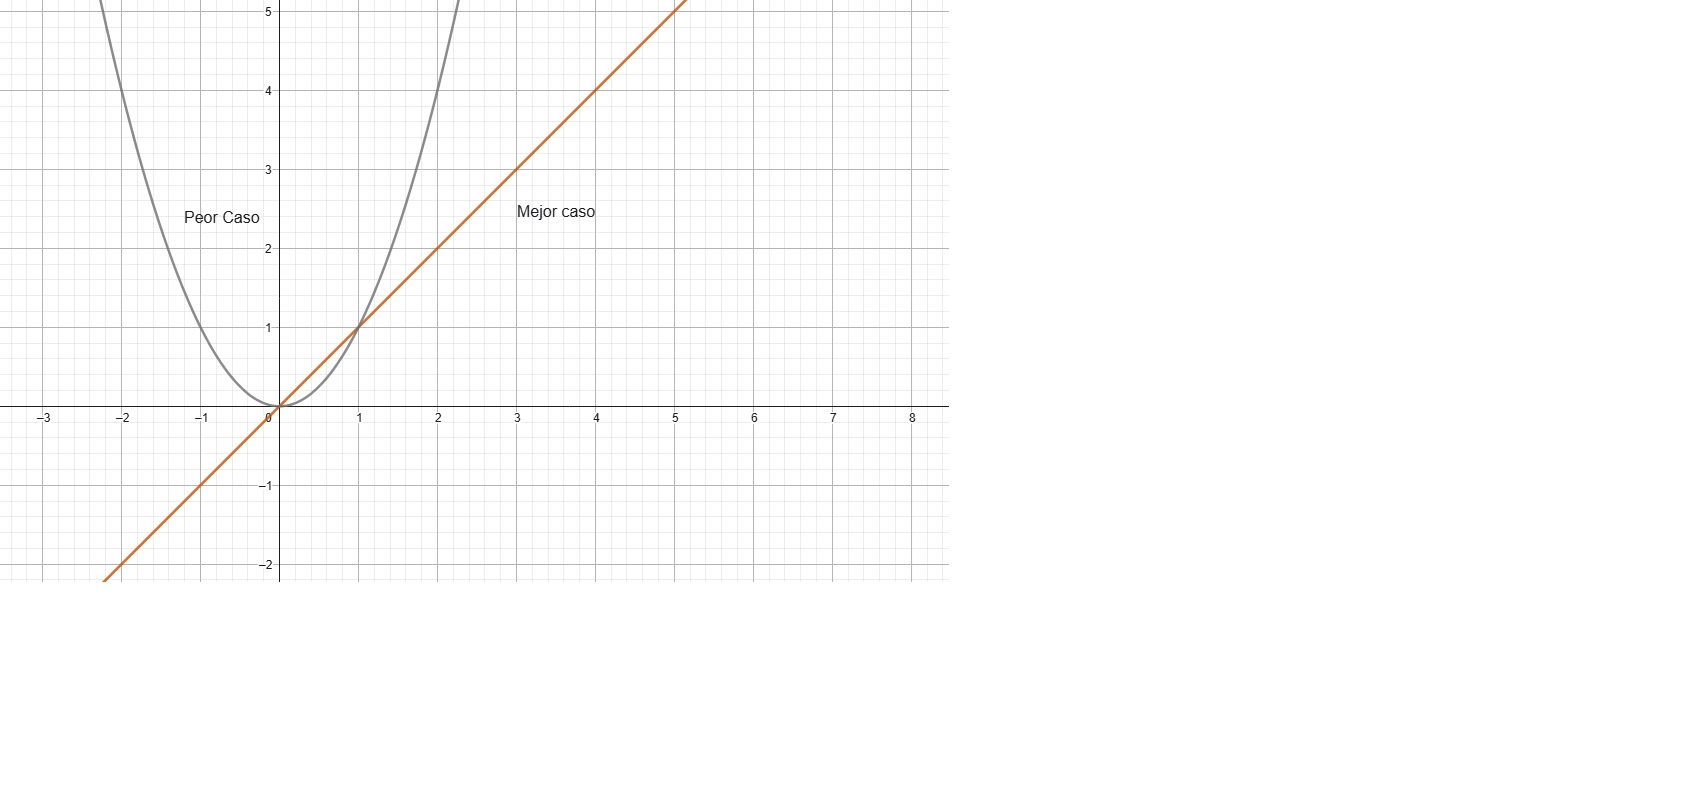

**3.**

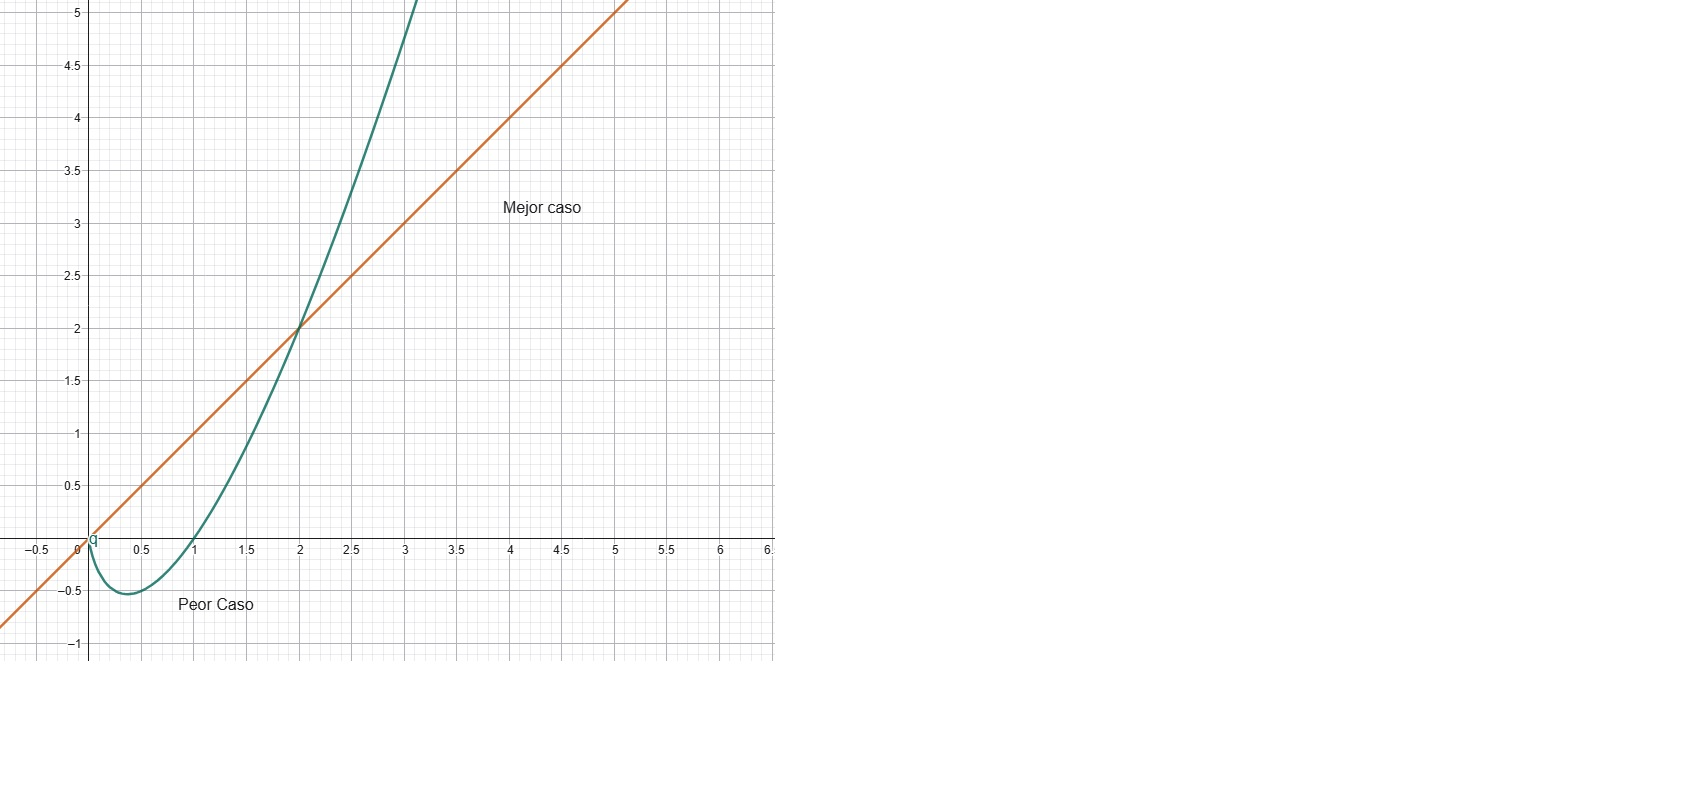

**4.**

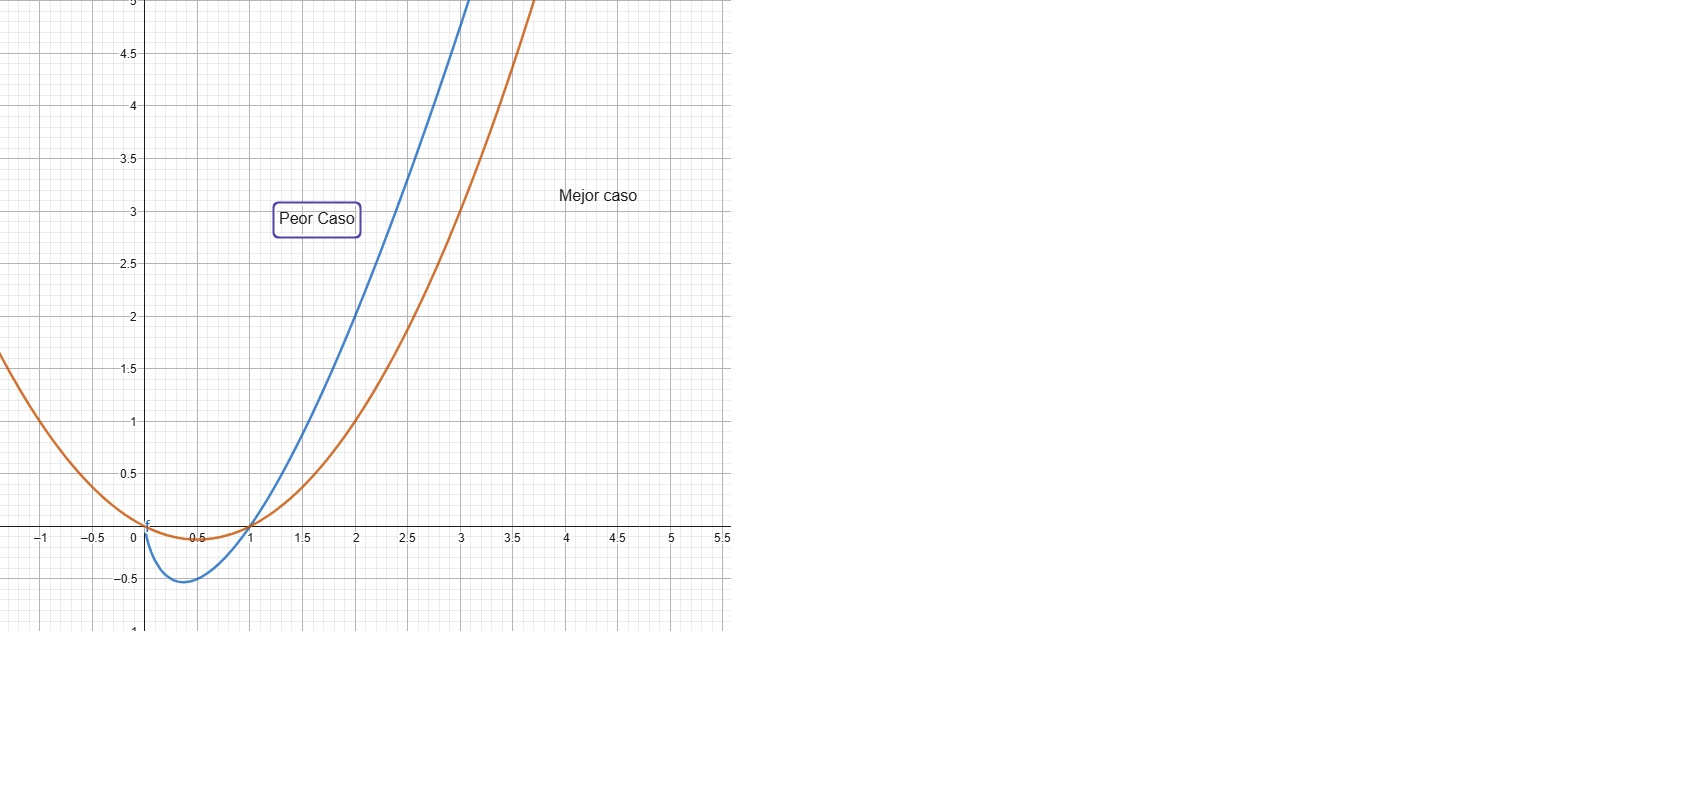

**5.**

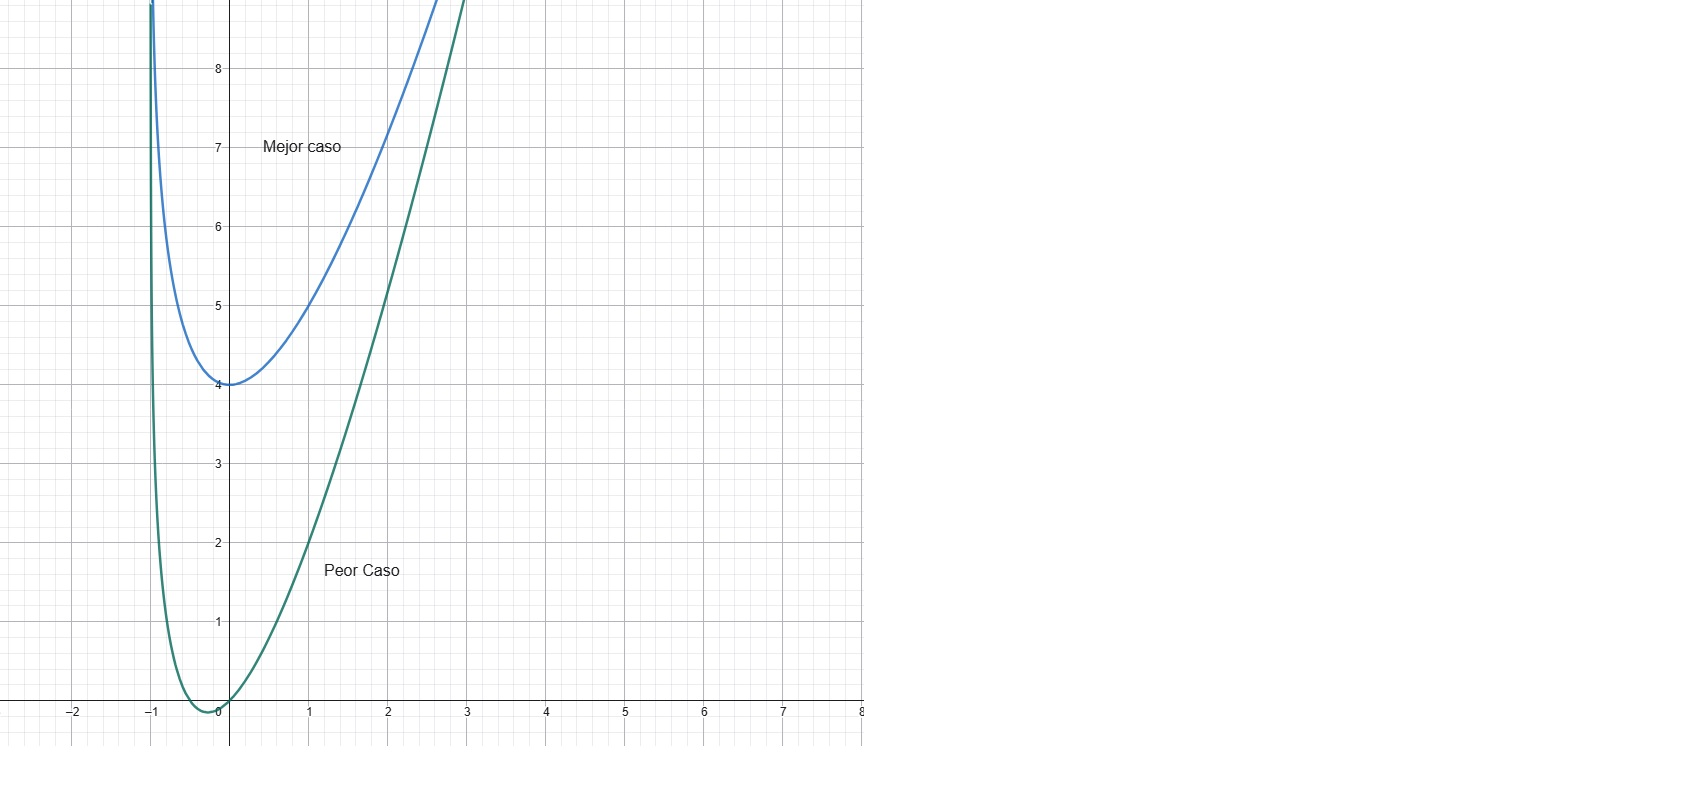

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


## Punto 1. **Cola de prioridad**

In [ ]:
import math
import matplotlib.pyplot as graf

tareas = [("T01", "Configurar servidor", 6), ("T02", "Reparar sensor", 10), ("T03", "Actualizar software", 4),
("T04", "Revisar camara", 8), ("T05", "Generar respaldo", 3), ("T06", "Configurar alarma", 7)]

def max_heapify(arr, tamano, i):
    izq = 2 * i + 1
    der = 2 * i + 2
    mayor = i

    if izq < tamano and arr[izq][2] > arr[mayor][2]:
        mayor = izq
    if der < tamano and arr[der][2] > arr[mayor][2]:
        mayor = der
    if mayor != i:
        arr[i], arr[mayor] = arr[mayor], arr[i]
        max_heapify(arr, tamano, mayor)

def build_max_heap(arr):
    tamano = len(arr)

    for i in range(tamano // 2 - 1, -1, -1):
        max_heapify(arr, tamano, i)

def texto_heap(arr):
    texto = []

    for tarea in arr:
        texto.append(tarea[0] + "(" + str(tarea[2]) + ")")
    return "[" + ", ".join(texto) + "]"

def dibujar_heap(arr, titulo):
    niveles = 1

    while 2 ** niveles - 1 < len(arr):
        niveles += 1
    posi = []

    for i in range(len(arr)):
        nivel = int(math.log2(i + 1))
        lugar = i - (2 ** nivel - 1)
        x = (lugar + 0.5) / (2 ** nivel)
        y = -nivel
        posi.append((x, y))

    graf.figure(figsize=(9, 2 * niveles))

    for i in range(1, len(arr)):
        madre = (i - 1) // 2
        graf.plot([posi[madre][0], posi[i][0]], [posi[madre][1], posi[i][1]], color="gray", zorder=1)
    for i in range(len(arr)):
        texto = arr[i][0] + "\n" + str(arr[i][2])
        graf.text(posi[i][0], posi[i][1], texto, ha="center", va="center", fontsize=10, bbox=dict(boxstyle="circle", facecolor="lightblue", edgecolor="black"), zorder=2)

    graf.title(titulo)
    graf.xlim(0, 1)
    graf.ylim(-(niveles - 1) - 0.6, 0.6)
    graf.axis("off")
    graf.show()

print("arr inicial:")
print(texto_heap(tareas))
print("Prioridades:", [tarea[2] for tarea in tareas])

heap = list(tareas)
build_max_heap(heap)

print()
print("Max-Heap resultante:")
print(texto_heap(heap))
print("Prioridades:", [tarea[2] for tarea in heap])

dibujar_heap(heap, "Max-Heap resultante")


## Punto 2. **Procesar tareas**

In [ ]:
def extract_max(arr):
    if len(arr) == 0:
        return None
    maximo = arr[0]
    ultimo = arr.pop()

    if len(arr) > 0:
        arr[0] = ultimo
        max_heapify(arr, len(arr), 0)
    return maximo

def insertar_tarea(arr, tarea):
    arr.append(tarea)
    i = len(arr) - 1

    while i > 0:
        madre = (i - 1) // 2

        if arr[madre][2] < arr[i][2]:
            arr[madre], arr[i] = arr[i], arr[madre]
            i = madre
        else:
            break

for _ in range(2):
    tarea = extract_max(heap)
    print("Tarea procesada:", tarea[0], "-", tarea[1], "- Prioridad", tarea[2])
    print("Heap resultante:", texto_heap(heap))
    print()
nueva = ("T07", "Falla en sistema contra incendios", 12)
insertar_tarea(heap, nueva)

print("Heap despues de insertar T07:")
print(texto_heap(heap))
print("Prioridades:", [tarea[2] for tarea in heap])

dibujar_heap(heap, "Max-Heap despues de insertar T07")

## Punto 3. **Dispositivos a conectar**

In [ ]:
dispo = [("A", "Servidor", 2, 2), ("B", "Camara", 7, 3), ("C", "Sensor", 4, 7),
("D", "Alarma", 10, 8), ("E", "Router", 13, 3), ("F", "Panel", 15, 7)]

graf.figure(figsize=(8, 5))

for letra, nombre, x, y in dispo:
    graf.scatter(x, y, color="blue", s=80, zorder=2)
    graf.text(x + 0.3, y + 0.3, letra + " - " + nombre)

graf.title("Posicion de los dispositivos")
graf.xlabel("X")
graf.ylabel("Y")
graf.xlim(0, 18)
graf.ylim(0, 10)
graf.grid(True)
graf.show()

cables = []

for i in range(len(dispo)):
    for j in range(i + 1, len(dispo)):
        dx = dispo[j][2] - dispo[i][2]
        dy = dispo[j][3] - dispo[i][3]
        distancia = math.sqrt(dx ** 2 + dy ** 2)
        cables.append((distancia, i, j))
print("Distancia entre cada pareja de dispo:")
for distancia, i, j in cables:
    print(dispo[i][0], "-", dispo[j][0], ":", format(distancia, ".2f"))

## Punto 4. **Árbol de Expansión Mínima**

In [ ]:
def buscar_raiz(padre, elemento):
    while padre[elemento] != elemento:
        padre[elemento] = padre[padre[elemento]]
        elemento = padre[elemento]
    return elemento

def unir(padre, tamano, a, b):
    raiz_a = buscar_raiz(padre, a)
    raiz_b = buscar_raiz(padre, b)

    if raiz_a == raiz_b:
        return False

    if tamano[raiz_a] < tamano[raiz_b]:
        raiz_a, raiz_b = raiz_b, raiz_a
    padre[raiz_b] = raiz_a
    tamano[raiz_a] += tamano[raiz_b]
    return True

cables.sort()
print("Aristas ordenadas por peso:")
for dist, i, j in cables:
    print(dispo[i][0], "-", dispo[j][0], ":", format(dist, ".2f"))
padre = list(range(len(dispo)))
tamano = [1] * len(dispo)
mst = []
costo_total = 0
conexiones = 0

print()
print("Proceso de Kruskal:")

for dist, a, b in cables:
    nombre_arista = dispo[a][0] + " - " + dispo[b][0]
    if unir(padre, tamano, a, b):
        mst.append((dist, a, b))
        costo_total += dist
        conexiones += 1
        print("Acepta", nombre_arista, ":", format(dist, ".2f"))

        if conexiones == len(dispo) - 1:
            break
    else:
        print("Rechaza", nombre_arista, ":", format(dist, ".2f"), "(forma ciclo)")
print()
print("Conexiones seleccionadas:")

for dist, a, b in mst:
    print(dispo[a][0], "-", dispo[b][0], ":", format(dist, ".2f"))
print("Numero de conexiones:", len(mst))
print("Longitud total de cable:", format(costo_total, ".2f"))

## Punto 5. **Visualización final**

In [ ]:
graf.figure(figsize=(9, 6))

for dist, a, b in mst:
    xa = dispo[a][2]
    ya = dispo[a][3]
    xb = dispo[b][2]
    yb = dispo[b][3]
    graf.plot([xa, xb], [ya, yb], color="green", linewidth=2, zorder=1)
    graf.text((xa + xb) / 2, (ya + yb) / 2, format(dist, ".2f"), ha="center", va="center", bbox=dict(facecolor="white", edgecolor="green", boxstyle="round"), zorder=3)

desplazamientos = {
    "A": (0.0, -0.9), "B": (0.3, -0.8), "C": (-0.3, 0.4),
    "D": (0.3, 0.4), "E": (0.3, -0.8), "F": (0.3, 0.4)}

for letra, nombre, x, y in dispo:
    graf.scatter(x, y, color="blue", s=100, zorder=2)
    graf.text(x + desplazamientos[letra][0], y + desplazamientos[letra][1], letra + " - " + nombre)
graf.title("Arbol de Expansion Minima (Kruskal)")
graf.xlabel("X")
graf.ylabel("Y")
graf.xlim(0, 18)
graf.ylim(0, 10)
graf.grid(True)
graf.text(9, 0.5, "Longitud total de cable: " + format(costo_total, ".2f"), ha="center", fontsize=12, bbox=dict(facecolor="lightyellow", edgecolor="black"))
graf.show()

## 7) Tests aplicados **[15 pts]**

In [ ]:
def es_max_heap(arr):
    for i in range(len(arr)):
        izq = 2 * i + 1
        der = 2 * i + 2
        if izq < len(arr) and arr[izq][2] > arr[i][2]:
            return False

        if der < len(arr) and arr[der][2] > arr[i][2]:
            return False
    return True

prueba = list(tareas)
build_max_heap(prueba)
assert [tarea[2] for tarea in prueba] == [10, 8, 7, 6, 3, 4]
assert es_max_heap(prueba)

assert extract_max(prueba)[0] == "T02"
assert es_max_heap(prueba)
assert extract_max(prueba)[0] == "T04"
assert [tarea[2] for tarea in prueba] == [7, 6, 3, 4]

insertar_tarea(prueba, ("T07", "Falla en sistema contra incendios", 12))
assert [tarea[2] for tarea in prueba] == [12, 7, 3, 4, 6]
assert es_max_heap(prueba)
assert [tarea[0] for tarea in heap] == [tarea[0] for tarea in prueba]
assert extract_max([]) is None

assert len(cables) == 15
assert len(mst) == 5
assert round(costo_total, 2) == 25.50
aristas_mst = []
for dist, a, b in mst:
    aristas_mst.append(dispo[a][0] + dispo[b][0])
assert sorted(aristas_mst) == ["AB", "BC", "BD", "DF", "EF"]
raiz = buscar_raiz(padre, 0)

for k in range(len(dispo)):
    assert buscar_raiz(padre, k) == raiz
print("Todas las pruebas assert finalizaron correctamente.")
